# Minimal drone RL — PPO with ONNX Runtime

Load `src/model/checkpoints/rnn_model2.onnx`, check the environment, train, and evaluate.
Restart the kernel after editing `lib`, then run all cells.
Historical experiment: `rnn_model2.onnx` is not included. Use `src/main_model.py` and `src/main_z.py` for the implemented PyTorch pipeline.

ONNX Runtime predicts normalized acceleration. `DroneEnv` from `lib` handles
output denormalization, dynamics, observations, reset, reward, and outcomes.


In [1]:
# Run once if needed, then restart the kernel:
# %pip install onnxruntime gymnasium stable-baselines3 numpy matplotlib scipy

import sys
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import onnxruntime as ort
from stable_baselines3 import PPO
from stable_baselines3.common.env_checker import check_env
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.results_plotter import load_results

PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "src/model/rnn_loader.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run from this project or src/policy/notebooks/ to find src/model/rnn_loader.py")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from policy.lib.droneEnv import DroneEnv, PARAMS, mission, run_episode, evaluate

SEED = 0
TOTAL_TIMESTEPS = 100000
LOG_DIR = PROJECT_ROOT / "results" / "onnx"
torch.set_num_threads(1)


## Load rnn_model2.onnx

Create one CPU ONNX Runtime session and pass a callable to `DroneEnv`.
This export takes `x` with shape `(1, 1000, 1)` and returns the corresponding
normalized acceleration sequence. It has no hidden-state input/output.

Keep each episode's commands in a zero-padded sequence and select the output
at the current step. The unidirectional RNN only uses the command prefix for
that prediction. The environment stores this history in `hidden_state` and
clears it on reset. The current 200-step episode fits within the 1000 samples.


In [2]:
model_path = PROJECT_ROOT / "src/model/checkpoints/rnn_model2.onnx"
session_options = ort.SessionOptions()
session_options.intra_op_num_threads = 1
session = ort.InferenceSession(
    str(model_path), sess_options=session_options, providers=["CPUExecutionProvider"]
)

def acceleration_rnn(u, history=None):
    if history is None:
        history = (np.zeros((1, 1000, 1), dtype=np.float32), 0)
    commands, step = history
    if step >= commands.shape[1]:
        raise ValueError("Episode exceeds the ONNX model's 1000-sample sequence")
    commands[0, step, 0] = float(u.item())
    predictions = session.run(None, {"x": commands})[0]
    return predictions[:, step:step + 1, :], (commands, step + 1)

print("Model:", model_path)
print("Input:", session.get_inputs()[0].name, session.get_inputs()[0].shape)
print("Output:", session.get_outputs()[0].name, session.get_outputs()[0].shape)


Model: /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/rnn_model/rnn_model2.onnx
Input: x ['batch', 1000, 1]
Output: linear_1001 ['batch', 1000, 1]


## 1. Environment

Use `DroneEnv` directly. Its observation is physical `[z, vz, az]`.
Its action is the standardized command `[u]` in `[-3, 3]`.
Reward, touchdown rules, mission, and episode length all come from `lib`.

Time and target altitude are not included in this observation.
Policies trained with the previous four-input observation need retraining.


In [3]:
env = DroneEnv(rnn_model=acceleration_rnn)
check_env(env)
obs, info = env.reset(seed=SEED)
print("Observation:", obs, env.observation_space)
print("Action:", env.action_space)
print("check_env: OK")


Observation: [ 0.     0.    -9.816] Box([  -5.  -20. -100.], [  5.  20. 100.], (3,), float32)
Action: Box(-3.0, 3.0, (1,), float32)
check_env: OK


/home/rayan768/venvs/main_env/lib/python3.13/site-packages/stable_baselines3/common/env_checker.py:515: UserWarning: We recommend you to use a symmetric and normalized Box action space (range=[-1, 1]) cf. https://stable-baselines3.readthedocs.io/en/master/guide/rl_tips.html
  warnings.warn(


In [4]:
env.reset(seed=SEED)
print(f"Initial state: {env.state}, t={env.t:.2f}, mission={mission(env.t):.2f}")

a = np.array([0.6], dtype=np.float32)
for _ in range(100):
    obs, reward, terminated, truncated, info = env.step(a)
    if terminated or truncated:
        break

print(f"State: {env.state}, t={env.t:.2f}, mission={mission(env.t):.2f}, outcome={info['outcome']}")


Initial state: [ 0.     0.    -9.816], t=0.00, mission=0.00
State: [ 5.22445  10.327446 10.733477], t=1.25, mission=0.00, outcome=lost


## 2. Baselines

Compare random actions over the library's action range with a constant zero
standardized command. Zero standardized command corresponds to `PARAMS.mean_u`
in physical command units; it is not a hover controller.
`evaluate` reports return and soft-landings using the library's outcome rules.
Reset is deterministic, so repeated deterministic flights do not measure robustness.


In [5]:
rng = np.random.default_rng(SEED)

def random_policy(obs):
    return rng.uniform(env.action_space.low, env.action_space.high).astype(np.float32)

def zero_policy(obs):
    return np.zeros(env.action_space.shape, dtype=np.float32)

for name, policy in [("Random", random_policy), ("Zero", zero_policy)]:
    print(f"{name:8s}", end=" ")
    evaluate(env, policy, n=10, seed=100)


Random   mean return:  -142.3 ±  62.3 | landed: 0/10
Zero     mean return:  -101.9 ±   0.0 | landed: 0/10


## 3. Train PPO

[PPO](https://stable-baselines3.readthedocs.io/en/master/modules/ppo.html)
accepts the continuous motor command. As in TD4, SB3 handles the neural
network and training loop; `Monitor` files record episode returns.
Increase `TOTAL_TIMESTEPS` if the flight still crashes or fails to land.

In [6]:
train_env = make_vec_env(
    lambda: DroneEnv(rnn_model=acceleration_rnn), n_envs=4, seed=SEED, monitor_dir=str(LOG_DIR)
)
agent = PPO(
    "MlpPolicy", train_env, seed=SEED, device="cpu",
    learning_rate=1e-4, n_steps=256, batch_size=128, verbose=0,
)
start = time.perf_counter()
agent.learn(total_timesteps=TOTAL_TIMESTEPS)
print(f"Trained for {agent.num_timesteps:,} steps in {time.perf_counter() - start:.1f} s")
train_env.close()


Trained for 100,352 steps in 392.8 s


## 4. Evaluate and inspect the flight

Use a separate environment and deterministic actions, without training exploration.
Compare the flight to the mission as well as checking the landing count.

PPO      mean return:  -162.6 ±   0.0 | landed: 0/10
Zero: crashed, return=-101.9, duration=0.25 s
PPO: flying, return=-162.6, duration=10.00 s


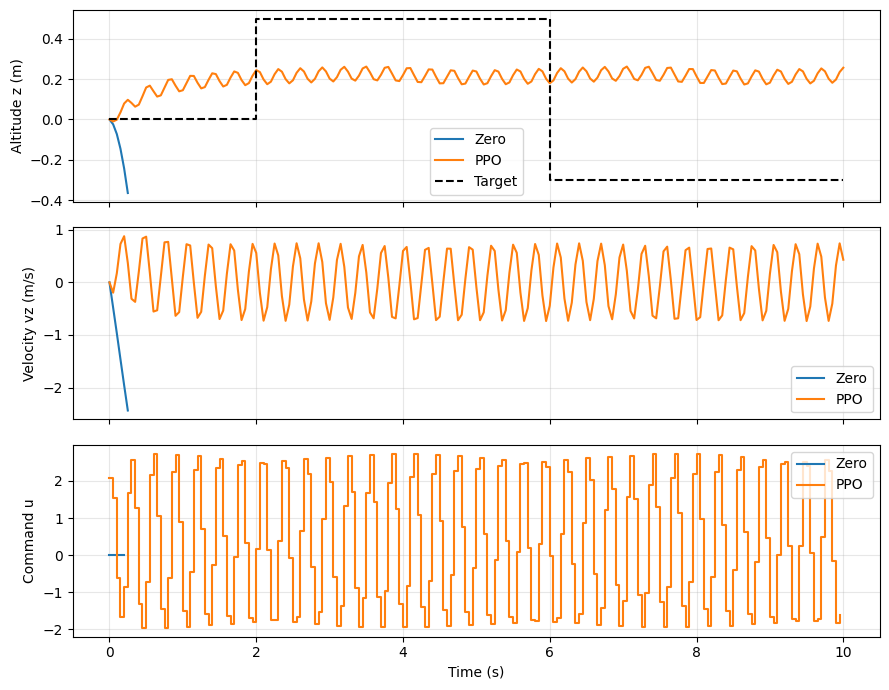

In [7]:
def ppo_policy(obs):
    return agent.predict(obs, deterministic=True)[0]

eval_env = DroneEnv(rnn_model=acceleration_rnn)
print("PPO     ", end=" ")
evaluate(eval_env, ppo_policy, n=10, seed=100)

fig, axes = plt.subplots(3, 1, figsize=(9, 7), sharex=True)
for name, policy in [("Zero", zero_policy), ("PPO", ppo_policy)]:
    states, actions, total, outcome = run_episode(eval_env, policy, seed=100)
    t = np.arange(len(states)) * PARAMS.dt
    axes[0].plot(t, states[:, 0], label=name)
    axes[1].plot(t, states[:, 1], label=name)
    axes[2].step(t[:-1], np.asarray(actions).reshape(-1), where="post", label=name)
    print(f"{name}: {outcome}, return={total:.1f}, duration={t[-1]:.2f} s")

reference_t = np.arange(env.max_steps + 1) * PARAMS.dt
axes[0].step(reference_t, [mission(t) for t in reference_t],
             where="post", color="black", linestyle="--", label="Target")
for ax, label in zip(axes, ["Altitude z (m)", "Velocity vz (m/s)", "Command u"]):
    ax.set_ylabel(label)
    ax.grid(alpha=0.3)
    ax.legend()
axes[2].set_xlabel("Time (s)")
fig.tight_layout()
plt.show()
eval_env.close()


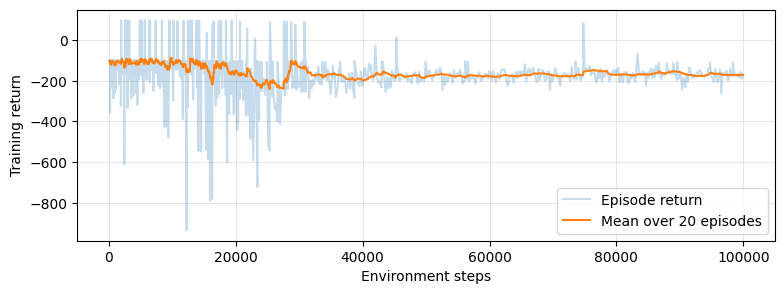

In [8]:
history = load_results(str(LOG_DIR))
returns = history["r"].to_numpy()
steps = history["l"].cumsum().to_numpy()
window = min(20, len(returns))

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(steps, returns, alpha=0.25, label="Episode return")
if window:
    smoothed = np.convolve(returns, np.ones(window) / window, mode="valid")
    ax.plot(steps[window - 1:], smoothed, label=f"Mean over {window} episodes")
ax.set(xlabel="Environment steps", ylabel="Training return")
ax.grid(alpha=0.3)
ax.legend()
plt.show()


## 5. Save and optional MATLAB export

The saved PPO agent can be loaded with `PPO.load("ppo_drone_rnn")`.
Set `EXPORT_MATLAB=True` to use the existing exporter. It writes `policy.mat`
and `traj_model.mat` in this directory.

MATLAB's observation must match `DroneEnv._obs()`: physical `[z, vz, az]`.
The policy outputs standardized commands in `[-3, 3]`; physical commands are
`u * PARAMS.sigma_u + PARAMS.mean_u`.
Check acceleration measurement timing when matching the exported trajectory;
the library also reports a previous-acceleration field.


In [9]:
agent.save("ppo_drone_rnn")
print("Saved ppo_drone_rnn.zip")

EXPORT_MATLAB = False
if EXPORT_MATLAB:
    from policy.export_policy import export_for_matlab
    export_env = DroneEnv(rnn_model=acceleration_rnn)
    export_for_matlab(agent, export_env)
    export_env.close()
env.close()


Saved ppo_drone_rnn.zip
